In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys

sys.path.append(os.path.abspath(".."))

import pandas as pd

from src.data_loader import load_fx, load_stocks

import matplotlib.pyplot as plt
from ipywidgets import interact

In [2]:
stocks = load_stocks()
fx = load_fx()

In [19]:
## checking date range, count of the rows, duplicated value (based on the date column)

stocks.groupby("ticker").agg(
    min_date = ("date","min"),
    max_date = ("date","max"),
    row = ("date","size"),
    max_open = ("open",max),
    max_close = ("close",max),
    duplicate_dates = ("date", lambda s:s.duplicated().sum()))

C:\Users\Adria\AppData\Local\Temp\ipykernel_20052\687455965.py:3: FutureWarning: The provided callable <built-in function max> is currently using SeriesGroupBy.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  stocks.groupby("ticker").agg(


,min_date,max_date,row,max_open,max_close,duplicate_dates
ticker,,,,,,
Alior,2015-01-01,2026-11-06,3014,142.899994,143.699997,0
ING,2015-01-01,2026-11-06,3014,483.000000,490.799988,0
Millennium,2015-01-01,2026-11-06,3014,23.870001,23.760000,0
PKO BP,2015-01-01,2026-11-06,3014,124.900002,124.540001,0
Pekao,2015-01-01,2026-11-06,3014,284.000000,283.100006,0
mBank,2015-01-01,2026-11-06,3014,1650.000000,1667.500000,0


In [21]:
fx.groupby("currency").agg(
    min_date = ("date","min"),
    max_date = ("date","max"),
    row = ("date","size"),
    max_rate = ("rate","max"),
    min_rate = ("rate","min"),
    duplicate_dates = ("date", lambda s: s.duplicated().sum())
)

,min_date,max_date,row,max_rate,min_rate,duplicate_dates
currency,,,,,,
CHF,2015-01-02,2026-11-09,2993,5.1200,3.4777,0
EUR,2015-01-02,2026-11-09,2993,4.9647,3.9822,0
USD,2015-01-02,2026-11-09,2993,5.0381,3.3173,0


In [5]:
def plot_ticker(ticker :str):
    df = stocks[stocks["ticker"] == ticker]
    fig, axes = plt.subplots(3,2, figsize = (12,12), sharex=True)

    axes[0, 0].plot(df["date"], df["open"], color= "steelblue", linewidth=1)
    axes[0, 1].plot(df["date"], df["close"], color= "steelblue", linewidth=1)
    axes[1, 0].plot(df["date"], df["high"], color= "steelblue", linewidth=1)
    axes[1, 1].plot(df["date"], df["low"], color= "steelblue", linewidth=1)
    axes[2, 0].plot(df["date"], df["adjclose"], color= "steelblue", linewidth=1)
    axes[2, 1].plot(df["date"], df["volume"], color= "steelblue", linewidth=1)
    
    axes[0,0].set_title("Open")
    axes[0,1].set_title("Close")
    axes[1,0].set_title("High")
    axes[1,1].set_title("Low")
    axes[2,0].set_title("Adjclose")
    axes[2,1].set_title("Volume")
    
    fig.suptitle(ticker, fontsize= 14, fontweight= "bold")
    fig.tight_layout()
    plt.show()
    
interact(plot_ticker, ticker=sorted(stocks["ticker"].unique()))

interactive(children=(Dropdown(description='ticker', options=('Alior', 'ING', 'Millennium', 'PKO BP', 'Pekao',…

<function __main__.plot_ticker(ticker: str)>

In [35]:
print(stocks.isna().sum())

date        0
ticker      0
currency    0
open        0
high        0
low         0
close       0
adjclose    0
volume      0
dtype: int64


In [37]:
print(fx.isna().sum())

date        0
currency    0
rate        0
dtype: int64


In [45]:
zero_volume = stocks[stocks["volume"] == 0]
print(zero_volume.groupby("ticker").size())

ticker
Alior         54
ING           52
Millennium    52
PKO BP        52
Pekao         52
mBank         78
dtype: int64


In [47]:
print(zero_volume.groupby("date").size().sort_values(ascending=False))

date
2015-01-01    6
2018-08-15    6
2019-01-01    6
2018-12-31    6
2018-12-26    6
             ..
2017-03-08    1
2017-03-09    1
2017-03-10    1
2017-03-13    1
2016-12-12    1
Length: 80, dtype: int64


<Axes: title={'center': 'NBM mid rates'}, xlabel='date'>

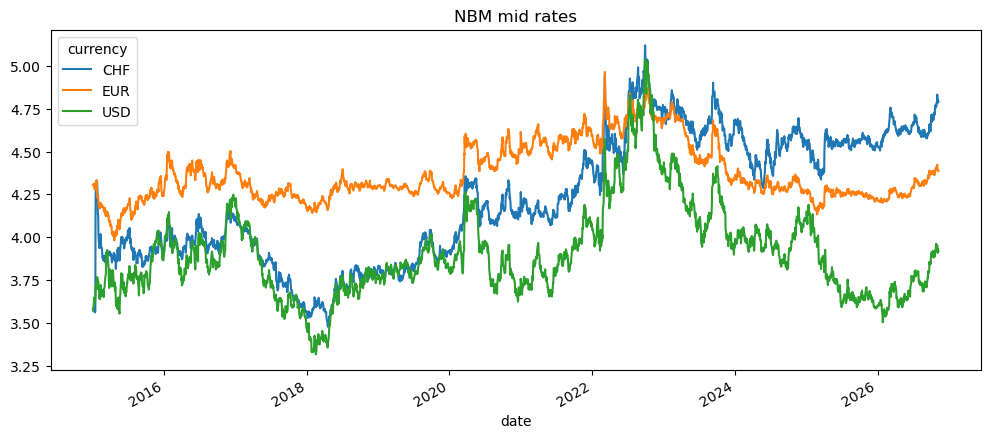

In [55]:
fx.pivot(index="date", columns = "currency", values="rate").plot(figsize = (12,5), title="NBM mid rates")

In [67]:
stock_dates = set(stocks["date"])
fx_dates = set(fx["date"])

print("Only in stocks:", len(stock_dates - fx_dates))
print("Only in FX:", len(fx_dates - stock_dates))

Only in stocks: 37
Only in FX: 16
